# Studiul de caz 1 - Criza prețurilor din vara anului 2024 și eficiența intervențiilor de urgență

Energy MBA - Analiza cantitativă a piețelor de energie (EMQA) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrarea de referință.** Andrei, A.-V., Pele, D.-T. și Cramer, A.-A. (2026). Evaluating intervention effectiveness during extreme price events:
a counterfactual analysis of Romania's 2024 energy crisis. *Proceedings of the International Conference on Business Excellence (PICBE)*, 20(1), 84-103. doi:10.2478/picbe-2026-0013

**Conținutul notebook-ului (replicare simplificată).** (1) Analizăm criza din iunie–iulie 2024 pe baza prețurilor orare de pe piața pentru ziua următoare (PZU) din România;
(2) estimăm un model Random Forest (RF, un ansamblu de arbori de regresie, „pădure aleatoare”) și o regresie Ridge pe variabilele fundamentale orare din perioada *anterioară* crizei; (3) evaluăm modelele pe datele din iunie–iulie 2024;
(4) construim scenarii contrafactuale: reducem cererea cu 5–30 %, adăugăm producție solară sau eoliană și urmărim cum se modifică prețul prognozat.

**Adaptarea pentru curs.** Lucrarea a folosit *prognozele* ENTSO-E (Rețeaua europeană a operatorilor de transport și de sistem pentru energie electrică) pentru ziua următoare
privind consumul și producția solară și eoliană, temperaturile, prețurile combustibililor și ultimele 5.000 de ore.
Noi folosim consumul și producția orară *efective* de pe energy-charts.info (în locul prognozelor, ceea ce echivalează cu ipoteza de „previziune perfectă”), prețuri *orare*, nicio variabilă meteorologică
și un eșantion de antrenare din perioada ianuarie 2023 – mai 2024. Rezultatele sînt valabile pentru aceste date și pentru această specificație.

## 1. Datele

In [2]:
p = cu.prices_hourly()                       # EUR/MWh, local time (Europe/Bucharest)
g = cu.generation_ro_hourly()                # MW (hourly mean)
x = cu.crossborder_ro_hourly()               # MW, + = net import into Romania
df = pd.DataFrame({"price": p["RO"], "price_hu": p["HU"], "price_de": p["DE_LU"]}).join(
     g[["load", "solar", "wind_onshore", "hydro_water_reservoir", "hydro_run_of_river", "gas", "nuclear", "brown_coal_lignite"]], how="inner").join(
     x[["sum"]].rename(columns={"sum": "net_import"}), how="left")
df = df.rename(columns={"wind_onshore": "wind", "hydro_water_reservoir": "hydro_res"})
df = df.loc["2022-06-01":"2024-08-31"].dropna(subset=["price", "load", "solar", "wind"])
CRISIS = ("2024-06-01", "2024-07-31")
print(df.shape, df.index.min(), df.index.max())
crisis = df.loc[CRISIS[0]:CRISIS[1]]
print("crisis window: mean price %.2f, max %.2f at %s" % (crisis.price.mean(), crisis.price.max(), crisis.price.idxmax()))

(19752, 12) 2022-06-01 00:00:00+03:00 2024-08-31 23:00:00+03:00
crisis window: mean price 121.84, max 916.72 at 2024-07-18 21:00:00+03:00


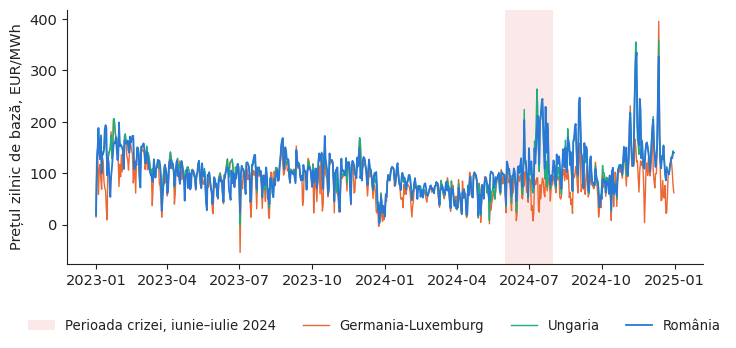

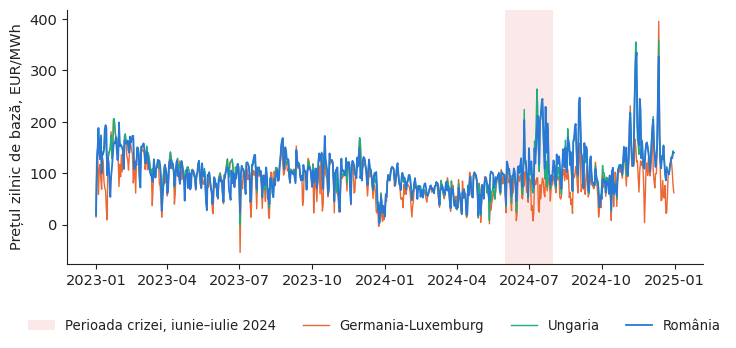

In [3]:
d = cu.prices_daily().loc["2023-01-01":"2024-12-31", ["RO", "HU", "DE_LU"]]
def fig_daily(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.3))
    ax.axvspan(pd.Timestamp(CRISIS[0]), pd.Timestamp(CRISIS[1]), color=cu.EVENT, alpha=0.12, lw=0,
               label=cu.T(lang, "June-July 2024 crisis window", "Perioada crizei, iunie–iulie 2024"))
    names = {"RO": cu.T(lang, "Romania", "România"), "HU": cu.T(lang, "Hungary", "Ungaria"), "DE_LU": cu.T(lang, "Germany-Luxembourg", "Germania-Luxemburg")}
    for z in ["DE_LU", "HU", "RO"]:
        ax.plot(d.index, d[z], color=cu.PAL[z], lw=1.0 if z != "RO" else 1.3, label=names[z])
    ax.set_ylabel(cu.T(lang, "Daily base price, EUR/MWh", "Prețul zilnic de bază, EUR/MWh"))
    cu.legend_bottom(fig, ncol=4)
    return fig
cu.save_both(fig_daily, "f1_daily_prices")

**Interpretarea graficului.** În iulie 2024, prețurile din România și din Ungaria se decuplează de cele din Germania: criza este una regională (Europa de Sud-Est), nu europeană.

## 2. În ce ore ale zilei au crescut brusc prețurile?

crisis: hour with highest mean price = 21 | mean price 332.3, mean solar 1 MW


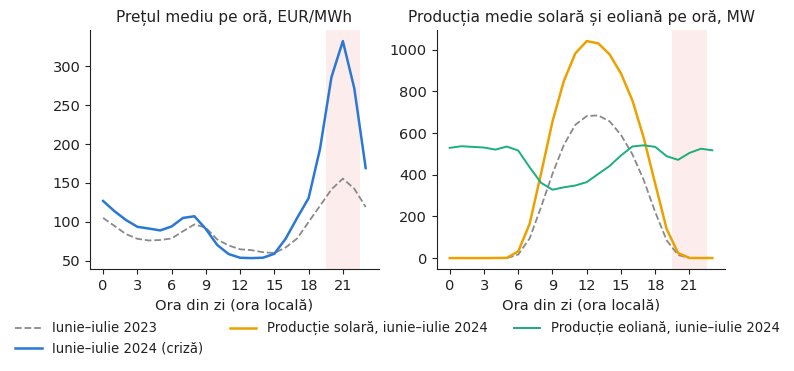

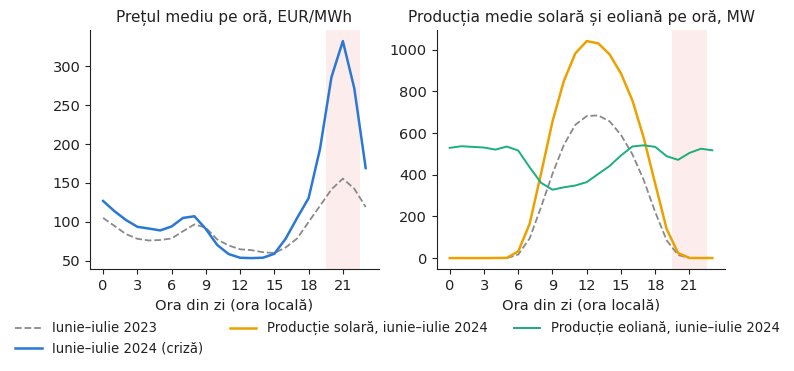

In [4]:
def hourly_profile(a, b):
    s = df.loc[a:b]
    return s.groupby(s.index.hour)[["price", "solar", "load", "wind"]].mean()
prof_c = hourly_profile(*CRISIS)
prof_n = hourly_profile("2023-06-01", "2023-07-31")
peak_hour = int(prof_c.price.idxmax())
print("crisis: hour with highest mean price =", peak_hour, "| mean price %.1f, mean solar %.0f MW" % (prof_c.price.max(), prof_c.solar[peak_hour]))
def fig_profile(lang):
    fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.1))
    a1, a2 = axes
    a1.plot(prof_n.index, prof_n.price, color=cu.MUTED, ls="--", label=cu.T(lang, "June-July 2023", "Iunie–iulie 2023"))
    a1.plot(prof_c.index, prof_c.price, color=cu.PAL["RO"], lw=1.8, label=cu.T(lang, "June-July 2024 (crisis)", "Iunie–iulie 2024 (criză)"))
    a1.set_title(cu.T(lang, "Mean price by hour, EUR/MWh", "Prețul mediu pe oră, EUR/MWh"))
    a2.plot(prof_n.index, prof_n.solar, color=cu.MUTED, ls="--")
    a2.plot(prof_c.index, prof_c.solar, color=cu.PAL["BG"], lw=1.8, label=cu.T(lang, "Solar, June-July 2024", "Producție solară, iunie–iulie 2024"))
    a2.plot(prof_c.index, prof_c.wind, color=cu.PAL["HU"], lw=1.4, label=cu.T(lang, "Wind, June-July 2024", "Producție eoliană, iunie–iulie 2024"))
    a2.set_title(cu.T(lang, "Mean solar and wind output by hour, MW", "Producția medie solară și eoliană pe oră, MW"))
    for a in axes:
        a.set_xlabel(cu.T(lang, "Hour of day (local time)", "Ora din zi (ora locală)")); a.set_xticks(range(0, 24, 3))
        a.axvspan(19.5, 22.5, color=cu.EVENT, alpha=0.10, lw=0)
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_profile, "f2_hourly_profile")

**Interpretarea graficului.** Criza s-a manifestat *seara*: prețurile au atins maximul după apusul soarelui, cînd producția solară este nulă, iar cererea rămîne ridicată
(banda evidențiată). Constatarea concordă cu episodul de vîrf din lucrare, pentru care prognoza producției solare era de numai 3 MW (lucrarea, Tabelul 1, p. 94).

## 3. Variabilele explicative și modelele

In [5]:
def features(z, oracle=True):
    """Hourly feature matrix with the information set at gate closure (12:00 CET on d-1): all PRICES up to day d-1 (lags >= 24 h; the d-1 auction
    cleared on d-2), REALISED fundamentals only up to day d-2 (lags >= 48 h), because d-1 is not yet metered at gate closure.
    oracle=True : load, solar and wind of hour t itself (ACTUAL values = perfect foresight, our proxy for the paper's day-ahead forecasts;
                  needed for the scenarios, which change the fundamentals of the spike hour; its accuracy is optimistic).
    oracle=False: information set at gate closure: load, solar and wind of the same hour on day d-2 (no forecasts in our data)."""
    idx0 = z.index
    z = z.asfreq("h")                                               # complete hourly grid: shift(k) = k elapsed hours, also across gaps
    f = pd.DataFrame(index=z.index)
    k = 0 if oracle else 48
    load, solar, wind = z.load.shift(k), z.solar.shift(k), z.wind.shift(k)
    f["load"] = load; f["solar"] = solar; f["wind"] = wind
    f["resid_load"] = load - solar - wind                          # residual load L_res = L - G_solar - G_wind (MW)
    f["ren_share"] = (solar + wind) / load                          # renewable share of load
    hr = z.index.hour
    f["peak_load"] = load * (((hr >= 8) & (hr <= 11)) | ((hr >= 18) & (hr <= 21)))   # peak-hour load interaction (paper: 8-11, 18-21)
    for c in ["hydro_res", "gas", "nuclear", "net_import"]:
        f[c + "_lag48"] = z[c].shift(48)                            # realised supply: day d-2 is the last fully metered day
    for L in [24, 48, 72, 168, 336]:
        f[f"price_lag{L}"] = z.price.shift(L)
    f["price_ma7"] = z.price.shift(24).rolling(168).mean()
    f["price_sd7"] = z.price.shift(24).rolling(168).std()
    for name, v, per in [("hour", hr, 24), ("dow", z.index.dayofweek, 7), ("month", z.index.month, 12)]:
        f[name + "_sin"] = np.sin(2 * np.pi * v / per); f[name + "_cos"] = np.cos(2 * np.pi * v / per)
    f = f.reindex(idx0)
    # DST days: an elapsed-hour lag can land one CET delivery day too late. Enforce the rule on the CET calendar:
    # 24-h price lags must lie in day d-1 or earlier, 48-h fundamental lags in day d-2 or earlier; otherwise drop the hour
    cet_day = lambda ix: ix.tz_convert("Europe/Brussels").normalize().tz_localize(None)
    d0 = cet_day(idx0)
    gap = lambda L: (d0 - cet_day(idx0 - pd.Timedelta(hours=L))).days
    f.loc[(gap(24) < 1) | (gap(48) < 2)] = np.nan
    return f

X_all = features(df); X_gc = features(df, oracle=False); y_all = df.price
ok = X_all.notna().all(axis=1) & X_gc.notna().all(axis=1)
X_all, X_gc, y_all = X_all[ok], X_gc[ok], y_all[ok]
cet_d = X_all.index.tz_convert("Europe/Brussels").tz_localize(None).normalize()   # CET delivery day of each hour
train = (cet_d >= "2023-01-01") & (cet_d < CRISIS[0])                 # split by delivery day: the last training day is the day before the test
test = (cet_d >= CRISIS[0]) & (cet_d <= CRISIS[1])
Xtr, ytr, Xte, yte = X_all[train], y_all[train], X_all[test], y_all[test]
Xtr_gc, Xte_gc = X_gc[train], X_gc[test]
print("train", Xtr.index.min().date(), "-", Xtr.index.max().date(), len(Xtr), "h | test", Xte.index.min().date(), "-", Xte.index.max().date(), len(Xte), "h")
print("max training price %.2f, max test price %.2f" % (ytr.max(), yte.max()))

train 2023-01-01 - 2024-06-01 12405 h | test 2024-06-01 - 2024-08-01 1464 h
max training price 436.89, max test price 916.72


In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

rf = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_split=10, min_samples_leaf=4,
                           max_features="sqrt", random_state=42, n_jobs=-1).fit(Xtr, ytr)   # paper's settings (p. 90)
ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": np.logspace(-2, 3, 30)},
                     cv=TimeSeriesSplit(5), scoring="neg_mean_squared_error").fit(Xtr, ytr)   # penalty by chronological CV; scaler refitted in each fold
rf_gc = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_split=10, min_samples_leaf=4,
                              max_features="sqrt", random_state=42, n_jobs=-1).fit(Xtr_gc, ytr)    # same RF, gate-closure information only
pred = pd.DataFrame({"actual": yte, "RF": rf.predict(Xte), "Ridge": ridge.predict(Xte), "RF_gc": rf_gc.predict(Xte_gc),
                     "Naive": Xte["price_lag24"]}, index=Xte.index)

def band_stats(m):
    rows = {}
    for lab, lo, hi in [("all", -np.inf, np.inf), ("<200", -np.inf, 200), ("200-500", 200, 500), (">500", 500, np.inf)]:
        s = pred[(pred.actual > lo) & (pred.actual <= hi)]
        rows[lab] = (mean_absolute_error(s.actual, s[m]), 100 * ((s.actual - s[m]) / s.actual).mean(), len(s))
    return rows
acc = {}
for m in ["Naive", "RF_gc", "Ridge", "RF"]:
    b = band_stats(m)
    acc[m] = {"R2": r2_score(pred.actual, pred[m]), "MAE": b["all"][0], "MAE_200_500": b["200-500"][0], "MAE_gt500": b[">500"][0],
              "Under_gt500": b[">500"][1]}
acc = pd.DataFrame(acc).T
n_gt500 = band_stats("RF")[">500"][2]
print("hours with price > 500 in the test window:", n_gt500)
cu.show_table(acc, best={"R2": "max", "MAE": "min", "MAE_200_500": "min", "MAE_gt500": "min"})

hours with price > 500 in the test window: 31


,R2,MAE,MAE_200_500,MAE_gt500,Under_gt500
Naive,0.58,41.56,110.71,180.13,15.80
RF_gc,0.47,35.38,116.61,441.44,64.35
Ridge,0.64,45.80,80.38,214.23,28.83
RF,0.55,32.35,97.99,406.80,59.06


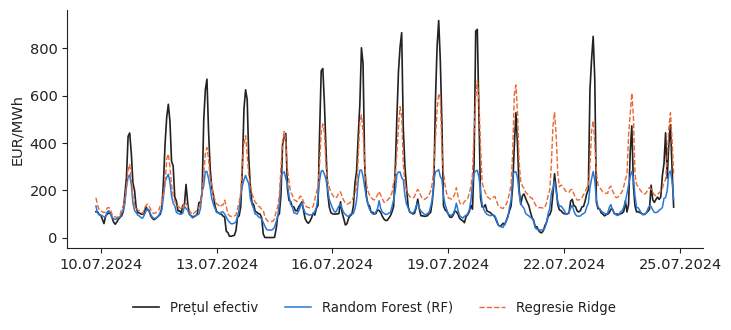

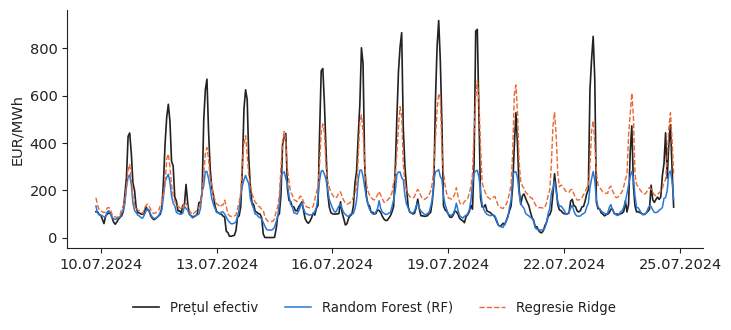

In [7]:
lab = {"Naive": ("Naive (price 24 h earlier)", "Naiv (prețul cu 24 de ore înainte)"),
       "RF_gc": ("RF, gate-closure information", "RF, informația de la închiderea porții"),
       "Ridge": ("Ridge, perfect foresight", "Ridge, previziune perfectă"),
       "RF": ("RF, perfect foresight", "RF, previziune perfectă")}
tab = acc.copy(); tab.index = [lab[i] for i in tab.index]
cu.write_table(tab, "accuracy",
    header=[("Model", "Model"), ("$R^2$", "$R^2$"), ("MAE", "MAE"), ("MAE 200--500", "MAE 200--500"), ("MAE $>$500", "MAE $>$500"),
            ("Under. $>$500, \\%", "Subestimare $>$500, \\%")],
    digits={"R2": 3, "MAE": 1, "MAE_200_500": 1, "MAE_gt500": 1, "Under_gt500": 1},
    best={"R2": "max", "MAE": "min", "MAE_200_500": "min", "MAE_gt500": "min", "Under_gt500": "absmin"})

wk = pred.loc["2024-07-10":"2024-07-24"]
def fig_fit(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.1))
    ax.plot(wk.index, wk.actual, color=cu.INK, lw=1.2, label=cu.T(lang, "Actual price", "Prețul efectiv"))
    ax.plot(wk.index, wk.RF, color=cu.PAL["RO"], lw=1.1, label=cu.T(lang, "Random Forest", "Random Forest (RF)"))
    ax.plot(wk.index, wk.Ridge, color=cu.PAL["DE_LU"], lw=1.0, ls="--", label=cu.T(lang, "Ridge regression", "Regresie Ridge"))
    ax.set_ylabel("EUR/MWh")
    cu.day_ticks(ax, lang, interval=3)
    cu.legend_bottom(fig, ncol=3)
    return fig
cu.save_both(fig_fit, "f3_model_fit")

**Interpretarea rezultatului.** Ambele modele *subestimează vîrfurile de seară*, deoarece au fost antrenate pe o perioadă în care prețurile au depășit rareori cîteva sute de EUR/MWh.
Înainte de a folosi într-o decizie nivelurile de preț estimate, verificați cît de sensibile sînt la alegerea perioadei de antrenare; o analiză de scenarii construită pe un astfel de model
indică mai bine *sensul și ordinea* efectelor intervențiilor decît nivelul absolut al prețului.

*Setul de informații.* Rîndurile RF și Ridge folosesc consumul și producția solară și eoliană *efective* din ora de livrare (previziune perfectă): acuratețea lor este optimistă,
nu o prognoză. Rîndul „RF, informația de la închiderea porții” folosește numai ceea ce se cunoaște la ora 12:00 CET în ziua d-1 (prețurile din ziua d-1 și variabilele fundamentale realizate din ziua d-2);
diferența dintre cele două rînduri RF măsoară valoarea unor prognoze bune ale variabilelor fundamentale pentru ziua următoare. Scenariile de mai jos folosesc modelul cu previziune perfectă,
deoarece modifică variabilele fundamentale chiar în ora cu vîrf de preț.

## 4. Scenarii contrafactuale

In [8]:
spike = Xte[yte > yte.quantile(0.95)]          # the 5 % most expensive crisis hours
peak_t = yte.idxmax()
print("spike hours:", len(spike), "| threshold %.1f EUR/MWh | peak hour %s, actual %.2f" % (yte.quantile(0.95), peak_t, yte.max()))

def scenario(X, dr=0.0, solar=0.0, wind=0.0):
    """Perturb the fundamentals and keep the derived features consistent (paper eq. 10-11)."""
    Z = X.copy()
    Z["load"] = X["load"] * (1 - dr); Z["solar"] = X["solar"] * (1 + solar); Z["wind"] = X["wind"] * (1 + wind)
    Z["resid_load"] = Z["load"] - Z["solar"] - Z["wind"]
    Z["ren_share"] = (Z["solar"] + Z["wind"]) / Z["load"]
    Z["peak_load"] = np.where(X["peak_load"] > 0, Z["load"], 0.0)
    return Z

rows = []
for name, kw in [("DR 5%", dict(dr=0.05)), ("DR 10%", dict(dr=0.10)), ("DR 20%", dict(dr=0.20)), ("DR 30%", dict(dr=0.30)),
                 ("Solar +50%", dict(solar=0.5)), ("Wind +100%", dict(wind=1.0)), ("Solar +50%, wind +50%, DR 5%", dict(solar=0.5, wind=0.5, dr=0.05))]:
    r = {}
    for m, mod in [("RF", rf), ("Ridge", ridge)]:
        base = mod.predict(spike); cf = mod.predict(scenario(spike, **kw))
        r[m + "_eur"] = (base - cf).mean()                          # reduction vs the model's own baseline, EUR/MWh
        r[m + "_pct"] = 100 * ((base - cf) / base).mean()
    r["mw"] = (spike["load"] * kw.get("dr", 0)).mean()
    rows.append(pd.Series(r, name=name))
scen = pd.DataFrame(rows)
cu.show_table(scen, best={"RF_eur": "max", "Ridge_eur": "max"})

spike hours: 74 | threshold 310.9 EUR/MWh | peak hour 2024-07-18 21:00:00+03:00, actual 916.72


,RF_eur,RF_pct,Ridge_eur,Ridge_pct,mw
DR 5%,5.33,2.22,8.12,2.34,385.72
DR 10%,16.89,6.96,16.23,4.67,771.44
DR 20%,56.08,22.67,32.42,9.33,1542.88
DR 30%,84.00,33.65,48.55,13.98,2314.31
Solar +50%,0.49,0.23,0.16,0.06,0.00
Wind +100%,8.00,3.27,3.63,1.09,0.00
"Solar +50%, wind +50%, DR 5%",10.71,4.49,10.05,2.93,385.72


Spearman rank correlation RF vs Ridge over 75 scenarios: 0.906


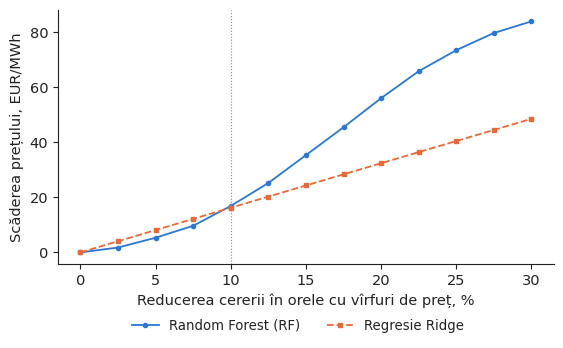

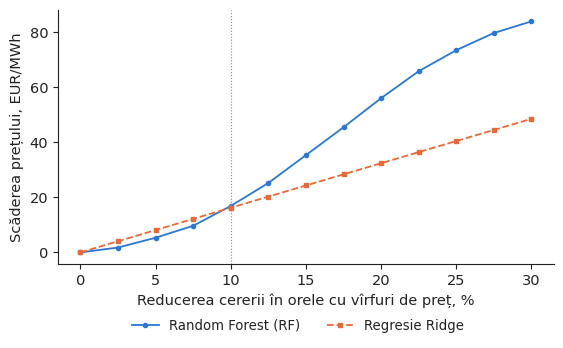

In [9]:
from scipy.stats import spearmanr
grid = []
for s_ in [0, 0.25, 0.5, 1.0, 2.0]:
    for w_ in [0, 0.25, 0.5, 1.0, 2.0]:
        for d_ in [0, 0.05, 0.10]:
            Z = scenario(spike, dr=d_, solar=s_, wind=w_)
            grid.append((s_, w_, d_, (rf.predict(spike) - rf.predict(Z)).mean(), (ridge.predict(spike) - ridge.predict(Z)).mean()))
grid = pd.DataFrame(grid, columns=["solar", "wind", "dr", "RF", "Ridge"])
rho = spearmanr(grid.RF, grid.Ridge).correlation
print("Spearman rank correlation RF vs Ridge over %d scenarios: %.3f" % (len(grid), rho))

drs = np.arange(0, 0.31, 0.025)
curve = pd.DataFrame({m: [(mod.predict(spike) - mod.predict(scenario(spike, dr=v))).mean() for v in drs] for m, mod in [("RF", rf), ("Ridge", ridge)]}, index=drs)
def fig_dr(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.3))
    ax.plot(100 * curve.index, curve.RF, color=cu.PAL["RO"], marker="o", ms=3, label=cu.T(lang, "Random Forest", "Random Forest (RF)"))
    ax.plot(100 * curve.index, curve.Ridge, color=cu.PAL["DE_LU"], marker="s", ms=3, ls="--", label=cu.T(lang, "Ridge regression", "Regresie Ridge"))
    ax.axvline(10, color=cu.MUTED, lw=0.8, ls=":")
    ax.set_xlabel(cu.T(lang, "Demand reduction in the spike hours, %", "Reducerea cererii în orele cu vîrfuri de preț, %"))
    ax.set_ylabel(cu.T(lang, "Price fall, EUR/MWh", "Scăderea prețului, EUR/MWh"))
    cu.comma_axis(ax, lang, "x", 0)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_dr, "f4_demand_response", headline=True)

**Interpretarea rezultatului.** Răspunsul cererii (DR, *demand response*) reduce prețul prognozat în orele de vîrf în ambele modele, iar *ordinea* scenariilor
este în mare măsură aceeași în RF și în Ridge (corelația Spearman de mai sus). Lucrarea obține aceeași ordine robustă (DR se află în primele 10 scenarii ale ambelor modele, Tabelul 3, p. 97).

*Prețurile de referință.* Lucrarea raportează prețurile din scenarii la prețul de vîrf **observat** (ec. 9); exercițiul nostru măsoară
variația dintre prognoza de **bază** a fiecărui model și prognoza din scenariu. Cele două procente au baze de raportare diferite,
de aceea trebuie prezentate separat.

## 5. Decizia: cît valorează un răspuns al cererii de 10 %?

In [10]:
dr10 = scen.loc["DR 10%"]
mwh_spike = (spike["load"] * 0.10).sum()                      # MWh curtailed if DR 10 % is called in every spike hour
saving_rf = ((rf.predict(spike) - rf.predict(scenario(spike, dr=0.10))) * spike["load"] * 0.9).sum()   # cheaper price on the remaining 90 % of load
print("DR 10%%: %.0f MW on average, %.0f MWh in %d spike hours" % (dr10.mw, mwh_spike, len(spike)))
print("RF: price falls by %.1f EUR/MWh (%.1f %%); bill saving for the remaining load %.2f million EUR" % (dr10.RF_eur, dr10.RF_pct, saving_rf / 1e6))

tab2 = scen[["RF_eur", "RF_pct", "Ridge_eur", "Ridge_pct", "mw"]].copy()
names = {"DR 5%": ("Demand response 5\\%", "Răspunsul cererii 5\\%"), "DR 10%": ("Demand response 10\\%", "Răspunsul cererii 10\\%"),
         "DR 20%": ("Demand response 20\\%", "Răspunsul cererii 20\\%"), "DR 30%": ("Demand response 30\\%", "Răspunsul cererii 30\\%"),
         "Solar +50%": ("Solar +50\\%", "Solar +50\\%"), "Wind +100%": ("Wind +100\\%", "Eolian +100\\%"),
         "Solar +50%, wind +50%, DR 5%": ("Solar +50\\%, wind +50\\%, DR 5\\%", "Solar +50\\%, eolian +50\\%, DR 5\\%")}
tab2.index = [names[i] for i in tab2.index]
cu.write_table(tab2, "scenarios",
    header=[("Scenario (spike hours)", "Scenariu (ore cu vîrfuri de preț)"), ("RF, EUR/MWh", "RF, EUR/MWh"), ("RF, \\%", "RF, \\%"),
            ("Ridge, EUR/MWh", "Ridge, EUR/MWh"), ("Ridge, \\%", "Ridge, \\%"), ("MW cut", "MW reduși")],
    digits={"RF_eur": 1, "RF_pct": 1, "Ridge_eur": 1, "Ridge_pct": 1, "mw": 0}, best={"RF_eur": "max", "Ridge_eur": "max"})

cu.write_numbers({
    "crisisMean": crisis.price.mean(), "crisisMax": crisis.price.max(),
    "peakTime": (f"{crisis.price.idxmax():%d %B %Y, %H:00}", f"{crisis.price.idxmax():%d.%m.%Y, ora %H:00}"),
    "peakHour": peak_hour, "peakSolar": prof_c.solar[peak_hour], "noonSolar": prof_c.solar[13],
    "evePrice": prof_c.price[peak_hour], "evePriceN": prof_n.price[peak_hour],
    "trainMax": ytr.max(), "nTrain": len(Xtr), "nTest": len(Xte), "nGt": n_gt500,
    "rfRtwo": acc.loc["RF", "R2"], "ridgeRtwo": acc.loc["Ridge", "R2"], "rfMAE": acc.loc["RF", "MAE"], "ridgeMAE": acc.loc["Ridge", "MAE"],
    "testStart": (f"{cet_d[test].min():%d %B %Y}", f"{cet_d[test].min():%d.%m.%Y}"), "testEnd": (f"{cet_d[test].max():%d %B %Y}", f"{cet_d[test].max():%d.%m.%Y}"),   # CET delivery days
    "naiveMAE": acc.loc["Naive", "MAE"], "gcRtwo": acc.loc["RF_gc", "R2"], "gcMAE": acc.loc["RF_gc", "MAE"], "gcUnder": acc.loc["RF_gc", "Under_gt500"],
    "rfUnder": acc.loc["RF", "Under_gt500"], "ridgeUnder": acc.loc["Ridge", "Under_gt500"],
    "nSpike": len(spike), "spikeThr": yte.quantile(0.95),
    "drTenRF": dr10.RF_eur, "drTenRFpct": dr10.RF_pct, "drTenRidge": dr10.Ridge_eur, "drTenRidgePct": dr10.Ridge_pct, "drTenMW": dr10.mw,
    "drTenMWh": mwh_spike, "drTenSave": saving_rf / 1e6, "rho": rho, "nGrid": len(grid),
    "solarRF": scen.loc["Solar +50%", "RF_eur"], "windRF": scen.loc["Wind +100%", "RF_eur"],
}, digits={"rfRtwo": 3, "ridgeRtwo": 3, "rho": 3, "peakSolar": 0, "noonSolar": 0, "drTenMW": 0, "drTenMWh": 0, "evePrice": 1, "evePriceN": 1,
           "rfMAE": 1, "ridgeMAE": 1, "naiveMAE": 1, "gcRtwo": 3, "gcMAE": 1, "gcUnder": 1, "rfUnder": 1, "ridgeUnder": 1, "drTenRF": 1, "drTenRFpct": 1, "drTenRidge": 1,
           "drTenRidgePct": 1, "solarRF": 1, "windRF": 1, "spikeThr": 1, "crisisMean": 1})
print("numbers written")

DR 10%: 771 MW on average, 57086 MWh in 74 spike hours
RF: price falls by 16.9 EUR/MWh (7.0 %); bill saving for the remaining load 8.21 million EUR
numbers written


In [11]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
LUNI = ["ianuarie", "februarie", "martie", "aprilie", "mai", "iunie", "iulie", "august", "septembrie", "octombrie", "noiembrie", "decembrie"]
for lang in ("en", "ro"):
    F = lambda v, nd=1: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    lines = [
        t("\\textbf{Summer-2024 crisis} (Andrei, Pele \\& Cramer, 2026, PICBE): counterfactual RF scenarios rank demand response as the Tier-1 lever; no intervention brings the peak below 200 EUR/MWh (p.~95).",
          "\\textbf{Criza din vara anului 2024} (Andrei, Pele și Cramer, 2026, PICBE): în scenariile contrafactuale estimate cu Random Forest, răspunsul cererii este pe primul loc; nicio intervenție nu coboară vîrful sub 200 EUR/MWh (p.~95)."),
        t(f"Our data: the crisis was an evening problem --- {F(crisis.price.max(), 2)} EUR/MWh on {crisis.price.idxmax():%d %B %Y at %H:00}; mean solar output at {peak_hour}:00 was {F(prof_c.solar[peak_hour], 0)} MW.",
          f"Datele cursului: criza s-a manifestat seara --- {F(crisis.price.max(), 2)} EUR/MWh pe {crisis.price.idxmax().day} {LUNI[crisis.price.idxmax().month - 1]} {crisis.price.idxmax().year}, la ora {crisis.price.idxmax():%H:00}; producția solară medie la ora {peak_hour}:00 a fost de {F(prof_c.solar[peak_hour], 0)} MW."),
        t(f"Our replication: a 10\\,\\% demand cut lowers spike-hour prices by {F(dr10.RF_eur)} EUR/MWh (RF) / {F(dr10.Ridge_eur)} (Ridge); solar +50\\,\\% changes almost nothing ({F(scen.loc['Solar +50%', 'RF_eur'])} EUR/MWh).",
          f"Replicarea noastră: o reducere a cererii cu 10\\,\\% scade prețul în orele de vîrf cu {F(dr10.RF_eur)} EUR/MWh (RF), respectiv cu {F(dr10.Ridge_eur)} EUR/MWh (Ridge); o producție solară mai mare cu 50\\,\\% nu schimbă aproape nimic ({F(scen.loc['Solar +50%', 'RF_eur'])} EUR/MWh)."),
        t(f"Lesson: trained on normal months, the RF underpredicts prices above 500 EUR/MWh by {F(acc.loc['RF', 'Under_gt500'], 0)}\\,\\% even with perfect foresight; with gate-closure information only, its MAE rises from {F(acc.loc['RF', 'MAE'])} to {F(acc.loc['RF_gc', 'MAE'])} EUR/MWh.",
          f"Concluzie: antrenat pe luni obișnuite, modelul RF subestimează prețurile de peste 500 EUR/MWh cu {F(acc.loc['RF', 'Under_gt500'], 0)}\\,\\% chiar și cu previziune perfectă; numai cu informația disponibilă la închiderea porții, MAE crește de la {F(acc.loc['RF', 'MAE'])} la {F(acc.loc['RF_gc', 'MAE'])} EUR/MWh."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Summer-2024 crisis} (Andrei, Pele \& Cramer, 2026, PICBE): counterfactual RF scenarios rank demand response as the Tier-1 lever; no intervention brings the peak below 200 EUR/MWh (p.~95).
  \item Our data: the crisis was an evening problem --- 916.72 EUR/MWh on 18 July 2024 at 21:00; mean solar output at 21:00 was 1 MW.
  \item Our replication: a 10\,\% demand cut lowers spike-hour prices by 16.9 EUR/MWh (RF) / 16.2 (Ridge); solar +50\,\% changes almost nothing (0.5 EUR/MWh).
  \item Lesson: trained on normal months, the RF underpredicts prices above 500 EUR/MWh by 59\,\% even with perfect foresight; with gate-closure information only, its MAE rises from 32.4 to 35.4 EUR/MWh.
\end{itemize}



## Exerciții suplimentare
1. Refaceți scenariile pentru o singură oră, cea cu prețul maxim, în locul celor 5 % din ore cu cele mai mari prețuri. Se schimbă ordinea scenariilor?
2. Adăugați *importurile nete* ca instrument în scenarii (+500 MW, măsura privind importurile din Nivelul 1 al lucrării). De ce este acest instrument mai greu de modelat?
3. Antrenați modelele doar pe ultimele 5.000 de ore dinaintea crizei (ca în lucrare). Cum se modifică R² și efectul DR?